# **Tutorial 10 - Neural ODEs**: Supplementary Interactive Material

-------------------------------------------------------------------------

In Tutorial 08 we knew the form of a differential equation and estimated its
parameters from observed trajectories. In Tutorial 09 we fitted a neural
network to samples of a function whose form we did not know. What if the
unknown function is the right-hand side of the differential equation itself,
and all we can observe are trajectories?

1. See that a residual network is a sequence of forward Euler steps, and take
   the limit of many small steps (Section 1).
2. Replace the right-hand side of an ODE by a network and fit it to observed
   trajectories, backpropagating through the ODE solver (Sections 2–3).
3. Vary the number of observed trajectories and ask where the learned vector
   field can be trusted (Section 4).

Run the cells in order. Each training run takes a few seconds; the slider in
Section 4 retrains whenever you release it.

In [1]:
import numpy as np
import torch
import torch.nn as nn
import torch.optim as optim
from torchdiffeq import odeint     # ODE solvers that PyTorch can backpropagate through
import matplotlib.pyplot as plt
from matplotlib.animation import FuncAnimation
import ipywidgets as widgets
from IPython.display import HTML, display

## 1. Residual networks as forward Euler steps

Each layer of the networks in Tutorial 09 replaced its input with a new vector,
$z_{k+1}=\mathrm{relu}(W_kz_k+b_k)$. A **residual network (ResNet)** instead
adds a correction to its input:

$$ z_{k+1}=z_k+f(z_k;\theta_k),\qquad k=0,\ldots,L-1, $$

where $f(\,\cdot\,;\theta_k)$ is a small network with parameters $\theta_k$.
Compare forward Euler from Tutorial 08:

$$ y_{n+1}=y_n+h\,f(t_n,y_n). $$

This is the same update, with $hf$ in place of $f$; a constant step size can
be absorbed into the weights of the network. If every layer shares the same
parameters $\theta$, a ResNet with $L$ layers takes $L$ Euler steps for the ODE
$\dot z=f(z;\theta)$. If the parameters change from layer to layer, the vector
field also depends on time. Either way, **depth plays the role of the number of
time steps.**

### Example 01: a residual block we can analyse

To see what a stack of residual layers does, give every layer the same block,
$z\mapsto z+hAz$, with

$$ A=\begin{pmatrix}0&-1\\1&0\end{pmatrix},\qquad\text{that is}\qquad
\dot x=-y,\quad \dot y=x. $$

The velocity $Az$ is always perpendicular to the position $z$, so the exact
solution rotates about the origin at unit angular speed and stays on its
starting circle:

$$ x(t)=x_0\cos t-y_0\sin t,\qquad y(t)=x_0\sin t+y_0\cos t. $$

The animation passes $z_0=(1,0)$ through 100 such layers with $h=0.1$, that
is, 100 Euler steps covering $0\le t\le10$, and plots every hidden state $z_k$.

**Before running the cell: the exact trajectory is a circle. Will the hidden
states stay on it, fall inside it, or drift outside it?**

In [2]:
def rotation(z):
    x, y = z
    return np.array([-y, x])                      # A z: always perpendicular to z

def exact_rotation(z0, t):
    x0, y0 = z0
    return np.column_stack([x0 * np.cos(t) - y0 * np.sin(t),
                            x0 * np.sin(t) + y0 * np.cos(t)])

def forward_euler(f, z0, h, n_steps):
    states = [np.array(z0, dtype=float)]
    for _ in range(n_steps):
        states.append(states[-1] + h * f(states[-1]))   # one residual layer: z + h f(z)
    return np.array(states)

z0 = np.array([1.0, 0.0])
h, n_steps = 0.1, 100
euler_states = forward_euler(rotation, z0, h, n_steps)
exact_states = exact_rotation(z0, h * np.arange(n_steps + 1))

fig, ax = plt.subplots(figsize=(5.5, 5.5))
euler_line, = ax.plot([], [], 'ro-', markersize=3, label='Euler steps (hidden states)')
exact_line, = ax.plot([], [], 'b--', label='Exact solution')
label = ax.text(0.03, 0.95, '', transform=ax.transAxes, fontsize=10,
                bbox=dict(boxstyle='round,pad=0.3', facecolor='white', alpha=0.8))
ax.set(xlim=(-2, 2), ylim=(-2, 2), aspect='equal', xlabel='x', ylabel='y',
       title=f'Forward Euler on a rotation, h = {h}')
ax.legend(loc='lower right')
ax.grid(alpha=0.3)

def update(frame):
    euler_line.set_data(euler_states[:frame + 1, 0], euler_states[:frame + 1, 1])
    exact_line.set_data(exact_states[:frame + 1, 0], exact_states[:frame + 1, 1])
    label.set_text(f'Layer k = {frame}, |z_k| = {np.linalg.norm(euler_states[frame]):.3f}')
    return euler_line, exact_line, label

ani = FuncAnimation(fig, update, frames=n_steps + 1, interval=50, blit=True)
plt.close(fig)
HTML(ani.to_jshtml())

Every Euler step moves at right angles to the current position, so it lands
outside the circle through $z_n$. Since $Az_n\perp z_n$ and $|Az_n|=|z_n|$,
Pythagoras gives

$$ |z_{n+1}|^2=|z_n|^2+h^2|Az_n|^2=(1+h^2)\,|z_n|^2 . $$

After 100 steps with $h=0.1$, the radius has grown by a factor of
$(1.01)^{50}\approx1.64$.

### A deeper network for the same total time

Now fix the total time at $T=2\pi$, one full revolution, so that the exact
solution returns to its starting point. Covering it with $L$ layers means a
step $h=T/L$, and the radius grows by

$$ (1+h^2)^{L/2}\approx e^{T^2/(2L)}=e^{hT/2}, $$

which tends to $1$ as $L\to\infty$. The error is $O(h)$, as Tutorial 08
predicted for Euler. In the limit, the stack of layers becomes the flow of the
ODE.

**Increase the number of layers. Roughly how many does the stack need to
return within $0.1$ of its starting point?**

In [3]:
def plot_depth(n_layers=10):
    T = 2 * np.pi                                 # one full revolution
    h = T / n_layers
    states = forward_euler(rotation, z0, h, n_layers)
    limit = 1.1 * np.abs(states).max()

    fig, ax = plt.subplots(figsize=(5.5, 5.5))
    ax.plot(*exact_rotation(z0, np.linspace(0, T, 200)).T, 'b--', label='Exact solution')
    ax.plot(*states.T, 'ro-', markersize=3, label=f'{n_layers} layers, h = {h:.3f}')
    ax.plot(*z0, 'ks', label='Input $z_0$')
    ax.set(xlim=(-limit, limit), ylim=(-limit, limit), aspect='equal', xlabel='x', ylabel='y',
           title=f'Distance from the exact output: $|z_L - z_0|$ = {np.linalg.norm(states[-1] - z0):.3f}')
    ax.legend(loc='best')
    ax.grid(alpha=0.3)
    plt.show()
    print(f'Radius growth over the stack: measured {np.linalg.norm(states[-1]):.4f}, '
          f'(1 + h^2)^(L/2) = {(1 + h**2)**(n_layers / 2):.4f}')


layer_slider = widgets.IntSlider(value=10, min=10, max=400, step=10, description='Layers',
                                 continuous_update=False)
output = widgets.interactive_output(plot_depth, {'n_layers': layer_slider})
display(widgets.VBox([layer_slider, output]))

A **neural ODE** takes this limit as its model. A network $f_\theta$ defines a
vector field, and the output for the input $z(0)$ is the state

$$ z(T)=z(0)+\int_0^T f_\theta(z(t))\,dt, $$

computed by an ODE solver. A ResNet is tied to Euler, with one step per layer.
A neural ODE can hand the integral to any solver: the midpoint method (RK2) from
Tutorial 08 brings this rotation back within $0.1$ of its start in about 20
steps.

> **Explore:** Write a function `rk2(f, z0, h, n_steps)` with the same inputs
> and outputs as `forward_euler`, using the midpoint step from Tutorial 08, and
> use it in `plot_depth`. How many steps does it need to return within $0.1$?
> Does its radius still grow?

## 2. Learning a vector field from trajectories

Tutorial 08 fitted two parameters of a right-hand side whose form we knew. Now
suppose we do not know its form at all. Replace the right-hand side with a
network,

$$ \dot z=f_\theta(z),\qquad z(0)=z_0, $$

and fit $\theta$ as in Tutorial 08. We observe $M$ trajectories, the $j$-th
starting from a known initial state $z_{0,j}$, at the times
$t_1,\ldots,t_N$:

$$ d_{ij}=z(t_i;z_{0,j})+\epsilon_{ij}. $$

For a trial $\theta$ we integrate the model from every initial state, giving
$z_\theta(t_i;z_{0,j})$, and minimize the mean squared residual over all
$2MN$ coordinates,

$$ L(\theta)=\frac1{2MN}\sum_{j=1}^M\sum_{i=1}^N
\big|z_\theta(t_i;z_{0,j})-d_{ij}\big|^2 . $$

Unlike Tutorial 09, we never observe the values of the function we are fitting.
The network only meets the data through the solution of the ODE.

### Gradients through the solver

How do we compute $\nabla L(\theta)$? In Tutorial 08 we used central finite
differences, which take two ODE solves per parameter. The network below has
1218 parameters, so a single gradient would take 2436 solves.

Section 1 suggests a better way. A fixed-step solver is a stack of residual
layers that all share $\theta$. PyTorch records every operation in every solver
step and backpropagates through them, just as it did through the layers in
Tutorial 09. One forward solve and one backward pass give the whole gradient.

The cost is memory: every intermediate state of the solver is stored for the
backward pass. The **adjoint method** avoids this by solving a second ODE
backward in time to recover the gradient; `torchdiffeq` provides it as
`odeint_adjoint`. For a two-dimensional system over a short time window,
storing the states is cheap, so we backpropagate directly through the solver.

### Example 02: a spiral sink

The trajectories come from a linear system that we treat as unknown:

$$ \dot x=-\alpha x-\omega y,\qquad \dot y=\omega x-\alpha y,
\qquad \alpha=0.1,\quad\omega=2. $$

This is the rotation from Section 1 at angular speed $\omega$, plus a weak pull
toward the origin. The matrix of this system has eigenvalues $-\alpha\pm i\omega$:
trajectories circle the origin with period $2\pi/\omega\approx3.1$, while their
radius decays like $e^{-\alpha t}$.

**Data.** We observe $M=40$ trajectories from initial states drawn uniformly
from the disc of radius 2. Each is measured at 41 evenly spaced times in
$0\le t\le2$, with Gaussian noise of standard deviation $0.05$ in each
coordinate. As in Tutorial 08, a solver with tight tolerances generates the
data, so its numerical error is small compared with the noise. A separate set
of 12 noise-free test trajectories, never used for training, will judge the fit.

In [4]:
alpha, omega = 0.1, 2.0
A_true = torch.tensor([[-alpha, -omega],
                       [ omega, -alpha]])

def true_field(t, z):
    return z @ A_true.T                   # each row of z is one state (x, y)

t_obs = torch.linspace(0, 2, 41)          # observation times
noise = 0.05                              # standard deviation of the measurement noise


def make_trajectories(n_trajectories, seed):
    generator = torch.Generator().manual_seed(seed)
    radius = 2 * torch.sqrt(torch.rand(n_trajectories, generator=generator))  # sqrt: uniform over the disc's area
    angle = 2 * np.pi * torch.rand(n_trajectories, generator=generator)
    z0 = torch.stack([radius * torch.cos(angle), radius * torch.sin(angle)], dim=1)    # shape (M, 2)
    with torch.no_grad():
        clean = odeint(true_field, z0, t_obs, rtol=1e-8, atol=1e-10)                # shape (N, M, 2)
    observed = clean + noise * torch.randn(clean.shape, generator=generator)
    return z0, observed, clean


z0_train, observed_train, _ = make_trajectories(40, seed=0)
z0_test, _, clean_test = make_trajectories(12, seed=1)    # new initial states, never used for training

print(f"Training initial states: {tuple(z0_train.shape)}, observations: {tuple(observed_train.shape)}")

Training initial states: (40, 2), observations: (41, 40, 2)


The left panel shows the true vector field, which the network never sees. The
dashed circle bounds the region the initial states are drawn from.

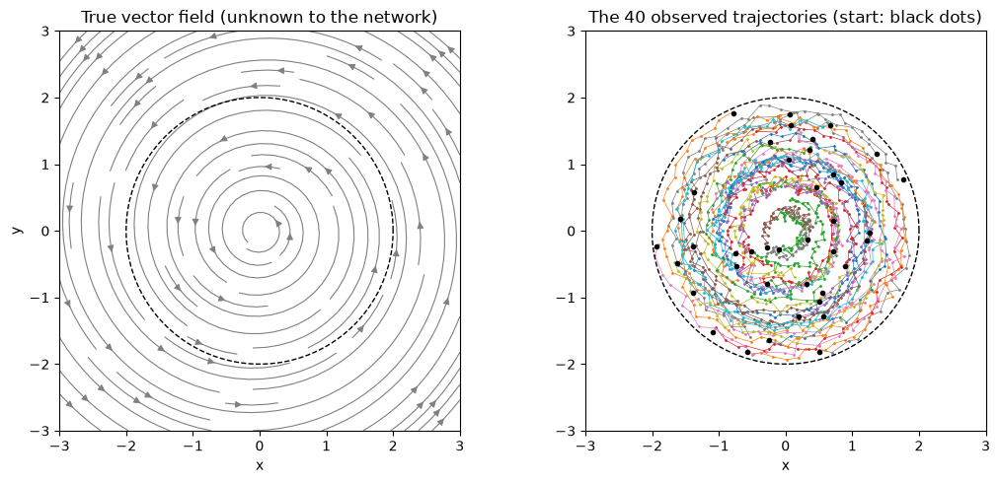

In [5]:
grid = np.linspace(-3, 3, 41)
grid_x, grid_y = np.meshgrid(grid, grid)
grid_points = torch.tensor(np.stack([grid_x, grid_y], axis=-1), dtype=torch.float32)   # shape (41, 41, 2)
true_values = true_field(None, grid_points).numpy()
circle = 2 * np.array([np.cos(np.linspace(0, 2 * np.pi, 200)), np.sin(np.linspace(0, 2 * np.pi, 200))])


def plot_field(ax, values, title):
    ax.streamplot(grid_x, grid_y, values[..., 0], values[..., 1], color='gray', density=1.0, linewidth=0.8)
    ax.plot(*circle, 'k--', linewidth=1)
    ax.set(xlim=(-3, 3), ylim=(-3, 3), aspect='equal', xlabel='x', ylabel='y', title=title)


fig, axes = plt.subplots(1, 2, figsize=(11, 5))
plot_field(axes[0], true_values, 'True vector field (unknown to the network)')
axes[1].plot(observed_train[:, :, 0], observed_train[:, :, 1], '.-', markersize=2, linewidth=0.5)  # one colour per trajectory
axes[1].plot(z0_train[:, 0], z0_train[:, 1], 'k.', markersize=6)
axes[1].plot(*circle, 'k--', linewidth=1)
axes[1].set(xlim=(-3, 3), ylim=(-3, 3), aspect='equal', xlabel='x',
            title=f'The {len(z0_train)} observed trajectories (start: black dots)')
plt.tight_layout()
plt.show()

**Model.** The network takes a state $(x,y)$ and returns a velocity
$(\dot x,\dot y)$. We use $\tanh$ rather than the ReLU of Tutorial 09, so that
$f_\theta$ is smooth, as the right-hand side of an ODE usually is. The solver
calls the right-hand side as `f(t, z)`, as `solve_ivp` did in Tutorial 08, so
`forward` takes the time as well; our vector field ignores it.

In [6]:
class VectorField(nn.Module):

    def __init__(self, hidden=32):
        super().__init__()
        self.net = nn.Sequential(
            nn.Linear(2, hidden), nn.Tanh(),          # state (x, y) -> hidden features
            nn.Linear(hidden, hidden), nn.Tanh(),
            nn.Linear(hidden, 2),                     # -> velocity (dx/dt, dy/dt)
        )

    def forward(self, t, z):
        return self.net(z)                            # autonomous: t is not used


def count_parameters(model):
    return sum(p.numel() for p in model.parameters())

**Solver.** `odeint(f, z0, times)` returns the solution at each entry of
`times`, like `solve_ivp` with `t_eval`. The argument `z0` may hold all $M$
initial states as rows, and the solver then integrates them together and returns
an array of shape $(N, M, 2)$. One call gives every predicted trajectory.

We use the midpoint method (RK2) from Tutorial 08 with a fixed step of $0.05$.
Each solve over $0\le t\le2$ is therefore a 40-layer residual network whose
layers all share $\theta$.

In [7]:
solver = dict(method='midpoint', options=dict(step_size=0.05))   # RK2 with a fixed step

def predict(field, z0, times):
    return odeint(field, z0, times, **solver)     # shape (len(times), M, 2)

**Training loop.** The loop is the one from Tutorial 09 with an ODE solve
inside the loss. Every iteration integrates all 40 trajectories at once, so we
use full batches and no `DataLoader`. Every few iterations we record the error
of the learned field on the grid and the predictions for the test trajectories.
We can measure that error only because we generated the data ourselves. As in
Tutorial 08, the truth is used to assess the fit, never to compute it.

In [8]:
def train_neural_ode(field, z0, observed, iterations=400, learning_rate=0.01, record_every=10):
    optimizer = optim.Adam(field.parameters(), lr=learning_rate)
    loss_history, snapshots = [], []
    for iteration in range(iterations):
        if record_every and iteration % record_every == 0:    # record the field error and test predictions
            with torch.no_grad():
                field_error = np.linalg.norm(field(None, grid_points).numpy() - true_values, axis=-1)
                snapshots.append((iteration, field_error, predict(field, z0_test, t_obs).numpy()))

        optimizer.zero_grad()
        loss = torch.mean((predict(field, z0, t_obs) - observed)**2)   # one solve for all trajectories
        loss.backward()                                                 # backpropagate through every solver step
        optimizer.step()
        loss_history.append(loss.item())

    return np.array(loss_history), snapshots

## 3. Fitting the spiral sink

We train a network with 1218 parameters on the 40 observed trajectories.

**Before running the cell: the observations contain noise with standard
deviation $0.05$. How low should the training loss go?**

In [9]:
torch.manual_seed(0)                              # same initial weights on each rerun
field = VectorField()
loss_history, snapshots = train_neural_ode(field, z0_train, observed_train)

with torch.no_grad():
    test_mse = torch.mean((predict(field, z0_test, t_obs) - clean_test)**2).item()
print(f"Parameters = {count_parameters(field)}, final training loss = {loss_history[-1]:.2e} "
      f"(noise variance = {noise**2:.2e}), test MSE = {test_mse:.2e}")

Parameters = 1218, final training loss = 2.53e-03 (noise variance = 2.50e-03), test MSE = 8.77e-05


The animation replays training. The left panel shows the error
$|f_\theta-f|$ of the learned field; the network itself never sees it. The dashed
circle bounds the region where the training trajectories start. On the right,
the black curves are the test trajectories and the dashed red curves are the
model's predictions from the same initial states.

**Where in the plane does the error disappear first? Where does it never
disappear?**

In [10]:
fig, (ax_error, ax_paths) = plt.subplots(1, 2, figsize=(11, 4.6))
error_image = ax_error.imshow(snapshots[0][1], extent=(-3, 3, -3, 3), origin='lower',
                              cmap='magma', vmin=0, vmax=3)
ax_error.plot(*circle, 'w--', linewidth=1)
ax_error.set(xlabel='x', ylabel='y', title=r'Error of the learned field $|f_\theta - f|$')
fig.colorbar(error_image, ax=ax_error, shrink=0.85)

ax_paths.plot(clean_test[:, :, 0], clean_test[:, :, 1], 'k-', linewidth=1)
predicted_lines = ax_paths.plot(clean_test[:, :, 0], clean_test[:, :, 1], 'r--', linewidth=1.2)
ax_paths.plot(*circle, 'k--', linewidth=1)
ax_paths.set(xlim=(-3, 3), ylim=(-3, 3), aspect='equal', xlabel='x',
             title='Test trajectories: true (black), predicted (red)')
label = ax_paths.text(0.03, 0.93, '', transform=ax_paths.transAxes, fontsize=10,
                      bbox=dict(boxstyle='round,pad=0.3', facecolor='white', alpha=0.8))
plt.tight_layout()

def update(frame):
    iteration, field_error, paths = snapshots[frame]
    error_image.set_data(field_error)
    for j, line in enumerate(predicted_lines):
        line.set_data(paths[:, j, 0], paths[:, j, 1])
    label.set_text(f'Iteration = {iteration}, loss = {loss_history[iteration]:.1e}')
    return (error_image, label, *predicted_lines)

ani = FuncAnimation(fig, update, frames=len(snapshots), interval=100, blit=True, repeat=True)
plt.close(fig)
HTML(ani.to_jshtml())

The training loss after every iteration, the final learned field, and its
error $|f_\theta-f|$ on the grid, with the training observations in white:

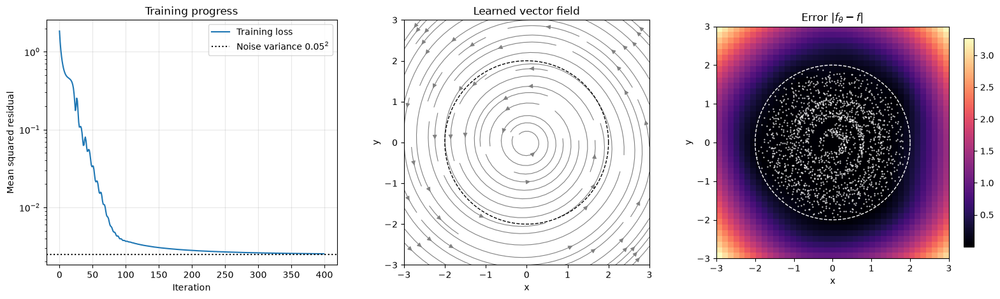

Mean |f_theta - f|: inside the disc = 0.042, outside = 1.005


In [11]:
with torch.no_grad():
    learned_values = field(None, grid_points).numpy()
error = np.linalg.norm(learned_values - true_values, axis=-1)

fig, axes = plt.subplots(1, 3, figsize=(16, 4.8))
axes[0].semilogy(loss_history, label='Training loss')
axes[0].axhline(noise**2, color='k', linestyle=':', label='Noise variance $0.05^2$')
axes[0].set(xlabel='Iteration', ylabel='Mean squared residual', title='Training progress')
axes[0].legend()
axes[0].grid(alpha=0.3)

plot_field(axes[1], learned_values, 'Learned vector field')

image = axes[2].imshow(error, extent=(-3, 3, -3, 3), origin='lower', cmap='magma')
axes[2].plot(observed_train[:, :, 0], observed_train[:, :, 1], 'w.', markersize=1)
axes[2].plot(*circle, 'w--', linewidth=1)
axes[2].set(xlabel='x', ylabel='y', title=r'Error $|f_\theta - f|$')
fig.colorbar(image, ax=axes[2], shrink=0.85)
plt.tight_layout()
plt.show()

inside = np.hypot(grid_x, grid_y) <= 2
print(f"Mean |f_theta - f|: inside the disc = {error[inside].mean():.3f}, "
      f"outside = {error[~inside].mean():.3f}")

### Did we recover $\alpha$ and $\omega$?

We never told the network that the system is linear, or what $\alpha$ and
$\omega$ are. Can we read them off the learned field anyway?

Near the origin, a smooth vector field is approximately linear:
$f_\theta(z)\approx f_\theta(0)+Jz$, where $J$ is the $2\times2$ Jacobian
matrix of partial derivatives at $z=0$. PyTorch computes $J$ by automatic
differentiation. If the network has learned the dynamics, then $J\approx A$, and
its eigenvalues should be close to $-\alpha\pm i\omega$.

In [12]:
def estimate_parameters(field):
    jacobian = torch.autograd.functional.jacobian(lambda z: field(None, z), torch.zeros(2))
    eigenvalue = np.linalg.eigvals(jacobian.numpy())[0]      # -alpha + i omega, or its conjugate
    return -eigenvalue.real, abs(eigenvalue.imag)

alpha_hat, omega_hat = estimate_parameters(field)
print(f"True:    alpha = {alpha:.4f}, omega = {omega:.4f}")
print(f"Learned: alpha = {alpha_hat:.4f}, omega = {omega_hat:.4f}")

True:    alpha = 0.1000, omega = 2.0000
Learned: alpha = 0.0996, omega = 1.9788


### What does the fit tell us?

The training loss levels off at the noise variance $0.05^2$, just as the
residuals did in Tutorial 08. The true trajectories do not pass through the
noisy observations either, so a much lower loss would mean that we had fitted
the noise. The test trajectories start from states the network never saw, and
the predictions still follow them. The network has learned a vector field, not
just the 40 training curves.

The error map shows where this holds. Inside the disc, where the training
trajectories run, the learned field is within a few hundredths of the true
field. Outside it, the network has never seen a state, so it is extrapolating,
and the error grows toward the corners. The true field grows linearly with
$|z|$, while the network's $\tanh$ units saturate, so its output cannot keep up
far from the data. Like the fits in Tutorials 07 and 09,
a neural ODE is constrained only where there are data. Here, *where* refers to
the state space, not to time.

The Jacobian at the origin recovers both parameters to within about $1\%$,
although we never wrote down a model containing them.

## 4. How much data does the vector field need?

In Tutorial 08, the **Observations** slider changed how many points we measured
along a single trajectory. Here the slider sets how many of the 40 training
trajectories we keep, and so how much of the plane the data visit. Each setting
uses the first $M$ trajectories and retrains a network from the same initial
weights.

The left panel shows the learned field with the observations it was trained on.
The right panel follows one test trajectory from $(1.5,0)$ to $t=10$, five times
the length of the training window (shaded).

**Move the slider from 40 trajectories to 1. Does the training loss still reach
the noise level? Does the model still predict the test trajectory, and does it
still recover $\alpha$ and $\omega$?**

In [ ]:
long_times = torch.linspace(0, 10, 201)           # five times the training window
long_start = torch.tensor([[1.5, 0.0]])            # a test initial state inside the disc

def fit_trajectories(n_trajectories=40):
    torch.manual_seed(0)                          # same initial weights for every choice
    field = VectorField()
    loss_history, _ = train_neural_ode(field, z0_train[:n_trajectories],
                                       observed_train[:, :n_trajectories], record_every=None)
    with torch.no_grad():
        learned_values = field(None, grid_points).numpy()
        test_mse = torch.mean((predict(field, z0_test, t_obs) - clean_test)**2).item()
        true_path = odeint(true_field, long_start, long_times, rtol=1e-8, atol=1e-10)[:, 0]
        learned_path = predict(field, long_start, long_times)[:, 0]
    alpha_hat, omega_hat = estimate_parameters(field)

    fig, axes = plt.subplots(1, 2, figsize=(13, 4.8), gridspec_kw={'width_ratios': [1, 1.4]})
    plot_field(axes[0], learned_values, f'Learned field, M = {n_trajectories}')
    axes[0].plot(observed_train[:, :n_trajectories, 0], observed_train[:, :n_trajectories, 1],
                 '.', markersize=3)
    axes[1].axvspan(0, 2, color='gray', alpha=0.15, label='Training window')
    axes[1].plot(long_times, true_path[:, 0], 'k-', label='True')
    axes[1].plot(long_times, learned_path[:, 0], 'r--', label='Neural ODE')
    axes[1].set(xlabel='t', ylabel='x(t)', title=f'Test trajectory from {tuple(long_start[0].tolist())}')
    axes[1].legend(loc='upper right')
    axes[1].grid(alpha=0.3)
    plt.tight_layout()
    plt.show()
    print(f"Training loss = {loss_history[-1]:.2e} (noise variance = {noise**2:.2e}), "
          f"test MSE = {test_mse:.2e}")
    print(f"True: alpha = {alpha:.4f}, omega = {omega:.4f} | "
          f"Learned: alpha = {alpha_hat:.4f}, omega = {omega_hat:.4f}")


trajectory_slider = widgets.IntSlider(value=40, min=1, max=40, description='Trajectories',
                                      continuous_update=False, style={'description_width': 'initial'})
output = widgets.interactive_output(fit_trajectories, {'n_trajectories': trajectory_slider})
display(widgets.VBox([trajectory_slider, output]))

### Where can we trust the learned model?

With one trajectory, the training loss still reaches the noise level, and can
even dip below it. The network finds a vector field whose solution passes
through that trajectory's observations. Many vector fields share that one solution, though, and away
from it the learned field is a guess. The test predictions and the recovered
$\alpha$ and $\omega$ show the difference. As in Tutorial 08, a small training
residual does not by itself show that we have recovered the model.

Each added trajectory constrains the field in another part of the plane. Once
the data cover the disc, the prediction stays accurate well beyond $t=2$. This
is not because the network has learned anything about later times. The spiral
sink keeps every trajectory inside the disc, where the field was trained. A
learned model can be trusted in the regions of the state space that the data
visited, for as long as its trajectories remain there.

> **Explore:** Start the long test trajectory outside the disc by setting
> `long_start = torch.tensor([[3.0, 0.0]])`. When does the prediction begin to
> go wrong? Does it recover once the trajectory enters the disc?
>
> Change the solver to forward Euler, `method='euler'`, and rerun from the
> **Solver** cell. The training loss still reaches the noise level. What
> happens to the recovered $\alpha$? Use the analysis from Section 1 to
> explain the change.
>
> Shorten the observation window to `t_obs = torch.linspace(0, 0.5, 11)` and
> rerun from Section 2. Which parameter becomes harder to recover? Compare
> this with ending the logistic observations at $t=2$ in Tutorial 08.

> **Discuss:** In Tutorial 08 we chose the form of the model and fitted two
> parameters. Here we fitted 1218 parameters and read $\alpha$ and $\omega$
> from the result. What does each approach require from the data? What can
> each tell us about states we never observed?